# mBART-50 pada IndoSum

Eksperimen ini memakai IndoSum sebagai baseline peringkasan abstraktif artikel berita bahasa Indonesia. Gunakan hasilnya untuk menilai kemampuan meringkas pada domain berita. Notebook tutorial memeriksa transfer ke domain coding. [Sumber resmi IndoSum](https://github.com/kata-ai/indosum)

## 1. Lingkungan dan konfigurasi

In [1]:
from datetime import datetime
import json
import os
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "requirements-training.txt").is_file())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

SEED = 42
MODE = os.environ.get("NLP_NOTEBOOK_MODE", "smoke")
if MODE not in {"smoke", "pilot"}:
    raise ValueError("NLP_NOTEBOOK_MODE harus smoke atau pilot.")
RUN_ID = datetime.now().strftime("%Y%m%d-%H%M%S-%f")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 120})
print(f"Mode {MODE} | Python {sys.version.split()[0]} | PyTorch {torch.__version__}")

from src.evaluation import ROUGE_TYPES, summary_metrics
from scripts.train_mbart_pilot import evaluate_lead3

DATA_DIR = ROOT / "data" / "processed" / "indosum"
RUN_DIR = ROOT / "outputs" / "notebooks" / "mbart-indosum" / RUN_ID
SPLITS = ("train", "validation", "test")
DOMAIN = False
if DOMAIN:
    LIMITS = (6, 3, 4) if MODE == "smoke" else (56, 6, 9)
    SOURCE_TOKENS, TARGET_TOKENS, LAYERS, LR = 256, 72, 2, 1e-4
else:
    LIMITS = (6, 3, 4) if MODE == "smoke" else (100, 20, 30)
    SOURCE_TOKENS, TARGET_TOKENS, LAYERS, LR = 512, 96, 1, 2e-5
EPOCHS = 1 if MODE == "smoke" else 3
PATIENCE = 2
print("GPU BF16 tersedia", torch.cuda.is_available() and torch.cuda.is_bf16_supported())
print("Jumlah contoh latih, validasi, uji", LIMITS)

Mode smoke | Python 3.11.15 | PyTorch 2.15.0+rocm10.2.0


<akar-repo>\.venv-rocm\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU BF16 tersedia True
Jumlah contoh latih, validasi, uji (6, 3, 4)


Gunakan kernel GPU PyTorch yang mendukung BF16. Mode `smoke` mengecek alur dengan sampel kecil dan satu epoch. Mode `pilot` memakai sampel lebih besar dengan maksimal tiga epoch. Setiap eksekusi mempunyai folder hasil sendiri sehingga metrik dan adapter eksperimen bisa ditelusuri.

## 2. Baca pasangan teks dan ringkasan

In [2]:
from itertools import combinations

corpus = {}
for split in SPLITS:
    path = DATA_DIR / f"{split}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"Siapkan {path} sesuai data/README.md.")
    frame = pd.read_csv(path, dtype={"id": str}, keep_default_na=False)
    valid = frame["text"].str.strip().ne("") & frame["summary"].str.strip().ne("")
    if not valid.all() or frame["id"].duplicated().any():
        raise ValueError(f"Split {split} berisi data kosong atau ID ganda.")
    corpus[split] = frame.assign(
        words=frame["text"].str.split().str.len(),
        reference_words=frame["summary"].str.split().str.len(),
    )
for first, second in combinations(SPLITS, 2):
    left, right = corpus[first], corpus[second]
    assert set(left["id"]).isdisjoint(right["id"])
    if DOMAIN:
        assert (set(left["video_id"]) - {""}).isdisjoint(set(right["video_id"]) - {""})
display(pd.DataFrame({
    split: {"contoh": len(frame), "median kata masukan": frame.words.median(),
            "median kata acuan": frame.reference_words.median()}
    for split, frame in corpus.items()
}).T)
display(corpus["train"][["id", "text", "summary"]].head(2))

,contoh,median kata masukan,median kata acuan
train,14261.0,324.0,67.0
validation,750.0,324.5,68.0
test,3762.0,325.0,67.0


,id,text,summary
0,1501893029-lula-kamal-dokter-ryan-thamrin-saki...,"Jakarta , CNN Indonesia - - Dokter Ryan Thamri...",Dokter Lula Kamal yang merupakan selebriti sek...
1,1509072914-dua-smartphone-zenfone-baru-tawarka...,Selfie ialah salah satu tema terpanas di kalan...,Asus memperkenalkan ZenFone generasi keempat ...


Kolom `text` menjadi masukan encoder dan `summary` menjadi target decoder. Pemeriksaan ID menangkap contoh yang tersalin antarsplit. Pada data tutorial, pemeriksaan juga membandingkan `video_id` agar potongan dari perekaman yang sama tidak bocor ke validasi atau uji.

## 3. Lihat komposisi dan panjang teks

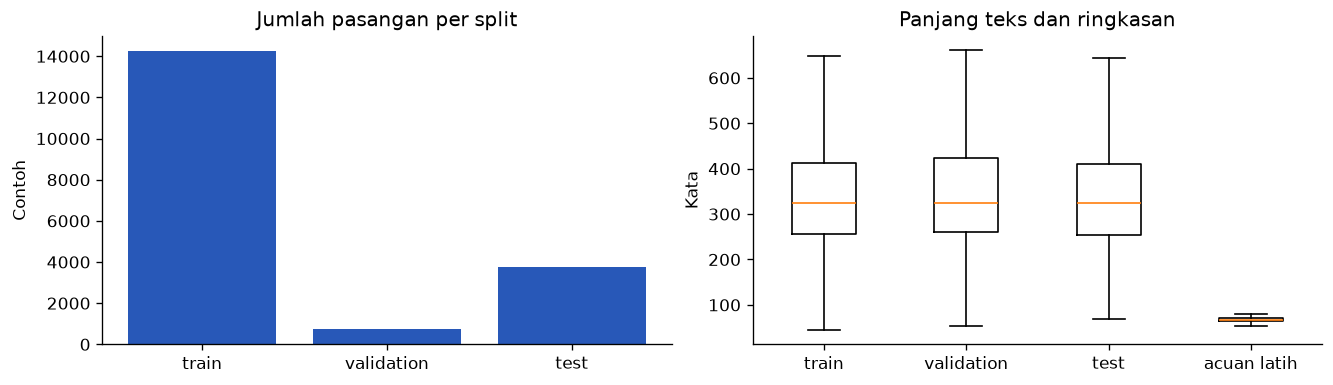

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.1), layout="constrained")
if DOMAIN:
    composition = pd.DataFrame({s: f["source"].value_counts() for s, f in corpus.items()}).fillna(0).T
    composition.plot.bar(stacked=True, ax=axes[0], rot=0, title="Asal pasangan per split")
else:
    axes[0].bar(SPLITS, [len(corpus[s]) for s in SPLITS], color="#2858b8")
    axes[0].set_title("Jumlah pasangan per split")
axes[0].set_ylabel("Contoh")
axes[1].boxplot([corpus[s]["words"] for s in SPLITS] + [corpus["train"]["reference_words"]],
                tick_labels=[*SPLITS, "acuan latih"], showfliers=False)
axes[1].set(title="Panjang teks dan ringkasan", ylabel="Kata")
plt.show()

Grafik pertama menunjukkan komposisi data yang tersedia. Di tutorial, contoh tambahan lintas tugas dan contoh sintetis masuk data latih, sementara validasi dan uji memakai tutorial Python Indonesia. Grafik panjang memakai jumlah kata sebagai gambaran awal. Batas konteks model tetap ditentukan dalam token subkata.

## 4. Ukur dampak batas token

In [4]:
from transformers import MBart50TokenizerFast

MODEL = "facebook/mbart-large-50"
tokenizer = MBart50TokenizerFast.from_pretrained(MODEL, src_lang="id_ID", tgt_lang="id_ID", local_files_only=True)
for split, count in zip(SPLITS, LIMITS, strict=True):
    probe = corpus[split].sample(n=count, random_state=SEED)
    token_counts = [len(tokenizer.encode(text, verbose=False)) for text in probe["text"]]
    print(split, f"{sum(n > SOURCE_TOKENS for n in token_counts)}/{len(probe)}",
          f"melebihi {SOURCE_TOKENS} token masukan")
display(pd.Series({"token bahasa sumber": "id_ID", "token bahasa target": "id_ID",
                   "awal generasi": tokenizer.eos_token, "batas target": TARGET_TOKENS}))

train 5/6 melebihi 512 token masukan
validation 0/3 melebihi 512 token masukan
test 1/4 melebihi 512 token masukan


token bahasa sumber    id_ID
token bahasa target    id_ID
awal generasi           </s>
batas target              96
dtype: object

Tokenizer mBART-50 membagi kata menjadi subkata dengan SentencePiece. Hitungan ini mengaudit potensi kehilangan bagian akhir sumber pada sampel diagnostik. Trainer menerapkan batas masukan dan target saat membentuk pasangan pelatihan serta membaca tag bahasa per baris jika tersedia.

## 5. Fine-tuning dan pemilihan epoch

In [5]:
if not (torch.cuda.is_available() and torch.cuda.is_bf16_supported()):
    raise RuntimeError("Pilih kernel PyTorch GPU BF16. Lihat notebooks/README.md.")
selection = "details" if DOMAIN else "rougeL"
command = [
    sys.executable, "-u", "-m", "scripts.train_mbart_pilot",
    "--data-dir", str(DATA_DIR.relative_to(ROOT)), "--output-dir", str(RUN_DIR.relative_to(ROOT)),
    "--train-samples", str(LIMITS[0]), "--validation-samples", str(LIMITS[1]),
    "--source-tokens", str(SOURCE_TOKENS), "--target-tokens", str(TARGET_TOKENS),
    "--decoder-layers", str(LAYERS), "--learning-rate", str(LR),
    "--epochs", str(EPOCHS), "--patience", str(PATIENCE), "--select-by", selection, "--compare-base",
]
subprocess.run(command, check=True, cwd=ROOT)
report = json.loads((RUN_DIR / "metrics.json").read_text(encoding="utf-8"))
display(pd.Series({k: report[k] for k in ("checkpoint", "best_epoch", "selection", "learning_rate",
                                        "lora_rank", "lora_alpha", "lora_dropout", "training_languages")}))

checkpoint            facebook/mbart-large-50@4ef55a20b36c6903b832e3...
best_epoch                                                            1
selection                                                        rougeL
learning_rate                                                   0.00002
lora_rank                                                             8
lora_alpha                                                           16
lora_dropout                                                       0.05
training_languages                                         {'id_ID': 6}
dtype: object

Skrip memakai LoRA pada proyeksi perhatian decoder, sehingga bobot dasar tetap beku. AdamW memperbarui adapter dengan cross-entropy dan gradient clipping 1,0. Learning rate tetap selama pelatihan mBART ini. Pada IndoSum, pemilihan epoch memakai ROUGE-L validasi. Pada tutorial, pemilihan mengutamakan cakupan detail acuan, lalu ROUGE-L jika seri. Early stopping berhenti setelah dua epoch tanpa perbaikan jika batas epoch belum tercapai.

## 6. Analisis kurva validasi

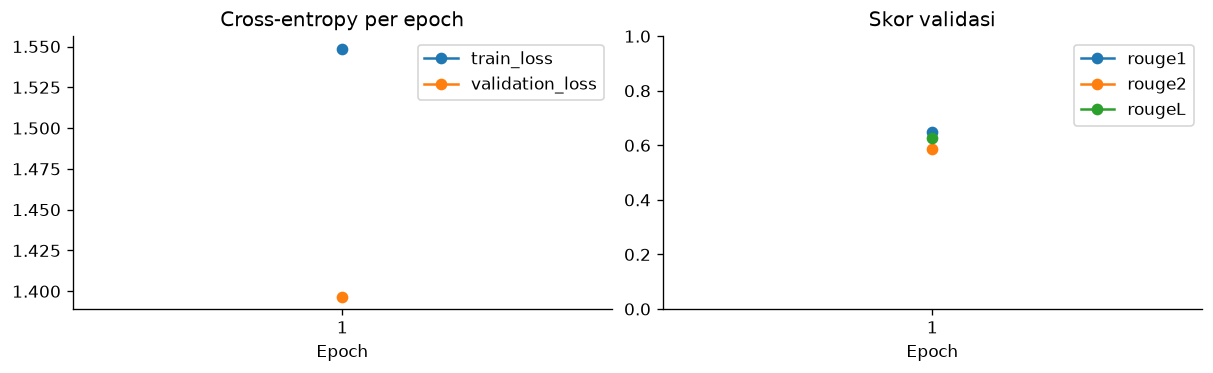

In [6]:
history = pd.read_json(RUN_DIR / "epoch_history.json")
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
history.plot(x="epoch", y=["train_loss", "validation_loss"], marker="o", ax=axes[0],
             title="Cross-entropy per epoch")
columns = ["rouge1", "rouge2", "rougeL"]
if "annotated_detail_recall" in history:
    columns.append("annotated_detail_recall")
history.plot(x="epoch", y=columns, marker="o", ax=axes[1], title="Skor validasi", ylim=(0, 1))
for ax in axes:
    ax.set_xticks(history["epoch"].to_list())
    ax.set_xlabel("Epoch")
plt.show()

Loss mengukur seberapa baik model memprediksi token target. ROUGE mengukur kemiripan teks hasil generasi dengan acuan. Jika loss latih turun tetapi loss validasi naik, cek kemungkinan overfitting. Dengan satu epoch hanya ada satu titik, sehingga grafik belum menunjukkan kecenderungan.

## 7. Evaluasi pada split uji

In [7]:
test_file = RUN_DIR / "test_report.json"
subprocess.run([
    sys.executable, "-u", "-m", "scripts.evaluate_mbart", str(RUN_DIR.relative_to(ROOT)),
    "--data-dir", str(DATA_DIR.relative_to(ROOT)), "--split", "test", "--limit", str(LIMITS[2]),
    "--output", str(test_file.relative_to(ROOT)),
], check=True, cwd=ROOT)
test = json.loads(test_file.read_text(encoding="utf-8"))
predictions = pd.DataFrame(test["predictions"])
selected = corpus["test"].set_index("id", drop=False).loc[predictions["id"]].to_dict("records")
lead3 = evaluate_lead3(selected)
display(pd.DataFrame([test["base"], test["tuned"], lead3], index=["mBART dasar", "mBART + LoRA", "Lead-3"]))
print("Jumlah prediksi base dan LoRA yang identik", test["identical_predictions"], "/", len(predictions))

,validation_loss,rouge1,rouge2,rougeL
mBART dasar,1.546863,0.779864,0.748244,0.764597
mBART + LoRA,1.547918,0.779864,0.748244,0.764597
Lead-3,NaN,0.794501,0.763615,0.778956


Jumlah prediksi base dan LoRA yang identik 4 / 4


Ketiga pembanding memakai baris uji yang sama. Lead-3 mengambil maksimal tiga kalimat awal dan menjadi baseline ekstraktif. Untuk fase uji, adapter berasal dari epoch yang sudah ditetapkan berdasarkan validasi. Jumlah prediksi identik membantu melihat apakah adapter mengubah keluaran.

## 8. Grafik ROUGE dan sebaran per contoh

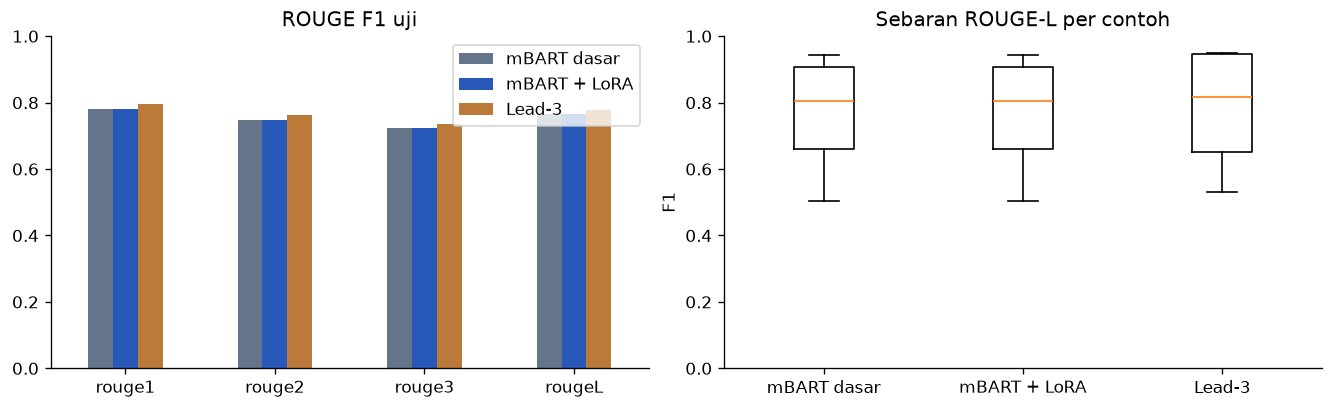

,mBART dasar,mBART + LoRA,Lead-3
rouge1,0.7799,0.7799,0.7945
rouge2,0.7482,0.7482,0.7636
rouge3,0.7236,0.7236,0.7353
rougeL,0.7646,0.7646,0.7790


In [8]:
def first_three(text):
    import re

    return " ".join(re.split(r"(?<=[.!?])\s+", text, maxsplit=3)[:3])

outputs = {
    "mBART dasar": predictions["baseline_prediction"].tolist(),
    "mBART + LoRA": predictions["prediction"].tolist(),
    "Lead-3": [first_three(row["text"]) for row in selected],
}
scores = {name: pd.DataFrame([summary_metrics(ref, out) for ref, out in
                             zip(predictions["reference"], generated, strict=True)])
          for name, generated in outputs.items()}
comparison = pd.DataFrame({name: item.mean() for name, item in scores.items()}).loc[list(ROUGE_TYPES)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), layout="constrained")
comparison.plot.bar(ax=axes[0], rot=0, color=["#64748b", "#2858b8", "#bb7a3a"], ylim=(0, 1), title="ROUGE F1 uji")
axes[1].boxplot([item["rougeL"] for item in scores.values()], tick_labels=list(scores))
axes[1].set(title="Sebaran ROUGE-L per contoh", ylabel="F1", ylim=(0, 1))
plt.show()
display(comparison.round(4))

ROUGE-1, ROUGE-2, dan ROUGE-3 menghitung kecocokan urutan satu, dua, dan tiga kata yang bersebelahan. ROUGE-L mengukur urutan kata yang cocok walaupun ada kata di antaranya. Semua batang menampilkan rerata F1 per pasangan referensi dan prediksi pada skala 0–1. Sebaran penting karena rata-rata dapat menyembunyikan contoh yang jauh lebih buruk.

## 9. Audit panjang dan contoh hasil ringkasan

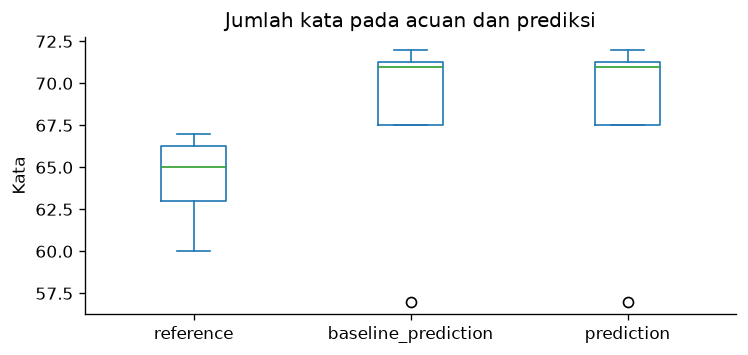

,id,reference,prediction,baseline_prediction,ROUGE-L LoRA
0,1492045823-telkom-indihome-akan-cabut-blokir-n...,Grup bisnis Telkom berencana mencabut blokir k...,Grup bisnis Telkom berencana mencabut blokir k...,Grup bisnis Telkom berencana mencabut blokir k...,0.943089
1,1509356898-42-kapal-akan-ditenggelamkan-susi-d...,Setelah melakukan penenggelaman 46 kapal pencu...,Setelah melakukan penenggelaman 46 kapal pencu...,Setelah melakukan penenggelaman 46 kapal pencu...,0.897196
2,1502431172-lenovo-k8-note-resmi-meluncur,Lenovo baru saja meluncurkan satu lagi smartph...,Lenovo baru saja meluncurkan satu lagi smartph...,Lenovo baru saja meluncurkan satu lagi smartph...,0.503817
3,1500710400-96-anak-rusun-di-jakarta-bakal-dila...,Yayasan Cahaya Kasih Tunas Bangsa bersama deng...,Yayasan Cahaya Kasih Tunas Bangsa bersama deng...,Yayasan Cahaya Kasih Tunas Bangsa bersama deng...,0.714286


In [9]:
predictions["ROUGE-L LoRA"] = scores["mBART + LoRA"]["rougeL"]
length = predictions[["reference", "baseline_prediction", "prediction"]].apply(
    lambda col: col.str.split().str.len()
)
ax = length.plot.box(figsize=(7, 3), title="Jumlah kata pada acuan dan prediksi")
ax.set_ylabel("Kata")
plt.show()
display(predictions[["id", "reference", "prediction", "baseline_prediction", "ROUGE-L LoRA"]].head(4))

Periksa apakah ringkasan terlalu panjang, mengulang kalimat sumber, atau menghapus informasi penting. ROUGE membantu mencari kasus untuk diperiksa. Penilaian fakta tetap perlu membandingkan prediksi dengan teks sumber.

## Kesimpulan yang bisa ditulis

Laporkan mode, revisi checkpoint, jumlah contoh, epoch terpilih, dan selisih skor pada data uji. Cantumkan satu contoh pola kesalahan dan bukti di sumber. ROUGE cocok untuk membandingkan teks ringkasan. ROC memerlukan kelas biner dan skor pemeringkat, sehingga grafik itu digunakan pada tugas tambahan deteksi risiko kesalahan di notebook Whisper.

## Hasil smoke lokal yang ditampilkan

Pada 4 contoh uji, ROUGE-L model dasar sebesar 0.7646 dan LoRA sebesar 0.7646. Sebanyak 4 dari 4 prediksi identik. Skor ini hanya menggambarkan smoke test satu epoch dan belum dapat dijadikan kesimpulan tentang generalisasi.